# Tema 13 · Modelos de Clasificación — Guía 1: Fundamentos y Métricas de Clasificación en Bolsa
**Curso:** Minería de Datos en Python (DM) · FISI · UNMSM · 2026-II · **Laboratorio 12 · Guía 1** · Docente: Prof. Mg. Ing. Ernesto D. Cancho-Rodríguez, MBA (GWU)

**Objetivo:** leer una matriz de confusión, calcular a mano precisión, exhaustividad y F1, y ver por qué la **exactitud engaña** con eventos raros. Se contrastan tres mundos con el **mismo código**: *Mundo 2* (sintético, evento raro), *Mundo 1* (¿sube SPY en 5 sesiones?: ruido) y *Mundo 3* (¿será agitado el próximo mes?: señal real).

**Datos:** Yahoo Finance (28 activos, 2010–19-nov-2026) con respaldo en CSV. **Entorno:** Google Colab, CPU. **Nada de este material es asesoría de inversión.**

# 1. Importación de librerías y carga de datos

In [1]:
# Librerías del laboratorio
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    brier_score_loss,
    roc_curve,
    precision_recall_curve,
)

warnings.filterwarnings("ignore")
SEMILLA = 2026  # semilla global: reproducibilidad
rng = np.random.default_rng(SEMILLA)
plt.rcParams.update(
    {"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3, "image.cmap": "viridis"}
)

In [2]:
# Precios ajustados de 28 activos hasta el cierre del 19-nov-2026. Si los 4 CSV del curso (carpeta D03) están junto al notebook se usan
# (las cifras coinciden con las de la guía); si no, se descargan de Yahoo Finance (pueden variar en centésimas si Yahoo revisó precios)
import os

TICKERS = [
    "SPY",
    "QQQ",
    "XLK",
    "XLF",
    "XLE",
    "XLV",
    "XLY",
    "XLP",
    "XLI",
    "XLU",
    "XLB",
    "XLRE",
    "XLC",
    "GLD",
    "TLT",
    "AAPL",
    "MSFT",
    "JPM",
    "XOM",
    "CAT",
    "KO",
    "PFE",
    "BVN",
    "FSM",
    "SCCO",
    "BHP",
    "B",
    "^VIX",
]
ARCH = {
    "cierres": "26.11.20.cierres_ajustados_28_activos_2010-01-04_2026-11-19.csv",
    "altos": "26.11.20.altos_ajustados_28_activos_2010-01-04_2026-11-19.csv",
    "bajos": "26.11.20.bajos_ajustados_28_activos_2010-01-04_2026-11-19.csv",
    "volumenes": "26.11.20.volumenes_28_activos_2010-01-04_2026-11-19.csv",
}
if all(os.path.exists(f) for f in ARCH.values()):
    cierres, altos, bajos, volumenes = [
        pd.read_csv(ARCH[k], index_col=0, parse_dates=True)
        for k in ["cierres", "altos", "bajos", "volumenes"]
    ]
    print("Se usó la foto de datos del curso (CSV)")
else:
    try:
        d = yf.download(
            TICKERS,
            start="2010-01-01",
            end="2026-11-20",
            auto_adjust=True,
            progress=False,
        )
        cierres, altos, bajos, volumenes = [
            d[c].reindex(columns=TICKERS) for c in ["Close", "High", "Low", "Volume"]
        ]
        print("Se descargó de Yahoo Finance")
    except Exception as e:
        raise SystemExit(
            "Falló la descarga de Yahoo Finance (%s): suba los 4 CSV del curso junto "
            "al notebook"
            % e
        )
for t in (cierres, altos, bajos, volumenes):
    t.index = pd.to_datetime(t.index)
print(
    "Dimensiones:",
    cierres.shape,
    "| desde",
    cierres.index.min().date(),
    "hasta",
    cierres.index.max().date(),
)
print(
    "Último cierre de SPY:",
    round(float(cierres["SPY"].dropna().iloc[-1]), 2),
    "| VIX:",
    round(float(cierres["^VIX"].dropna().iloc[-1]), 2),
)

Se usó la foto de datos del curso (CSV)
Dimensiones: (4249, 28) | desde 2010-01-04 hasta 2026-11-19
Último cierre de SPY: 715.87 | VIX: 28.44


# 2. Parte I — La matriz de confusión y las métricas, a mano
Con 10 alertas de un sistema que avisa «mañana habrá un evento»: VP = verdaderos positivos (aviso y ocurrió), FP = falsos positivos (aviso y no ocurrió), FN = falsos negativos (no aviso y ocurrió), VN = verdaderos negativos.

In [3]:
# Ejemplo mínimo: 10 casos reales y 10 predicciones
real = np.array([1, 1, 1, 1, 0, 0, 0, 0, 0, 0])
pred = np.array([1, 1, 1, 0, 1, 1, 0, 0, 0, 0])
vp = int(((real == 1) & (pred == 1)).sum())
fp = int(((real == 0) & (pred == 1)).sum())
fn = int(((real == 1) & (pred == 0)).sum())
vn = int(((real == 0) & (pred == 0)).sum())
print("VP, FP, FN, VN =", vp, fp, fn, vn)
print("Exactitud     =", (vp + vn) / 10, "| sklearn:", accuracy_score(real, pred))
print(
    "Precisión     =",
    round(vp / (vp + fp), 3),
    "| sklearn:",
    round(precision_score(real, pred), 3),
)
print(
    "Exhaustividad =",
    round(vp / (vp + fn), 3),
    "| sklearn:",
    round(recall_score(real, pred), 3),
)
f1_mano = (
    2 * (vp / (vp + fp)) * (vp / (vp + fn)) / ((vp / (vp + fp)) + (vp / (vp + fn)))
)
print(
    "F1            =", round(f1_mano, 3), "| sklearn:", round(f1_score(real, pred), 3)
)
print(confusion_matrix(real, pred))

VP, FP, FN, VN = 3 2 1 4
Exactitud     = 0.7 | sklearn: 0.7
Precisión     = 0.6 | sklearn: 0.6
Exhaustividad = 0.75 | sklearn: 0.75
F1            = 0.667 | sklearn: 0.667
[[4 2]
 [1 3]]


# 3. Parte II — Laboratorio de contraste sintético (Mundo 2): el evento raro
Un evento que ocurre en el **1 %** de los días (por ejemplo, una caída extrema) y variables con señal plantada. El modelo que **siempre dice «no hay evento»** acierta el 99 % de las veces y no detecta nada.

In [4]:
# Datos sintéticos con evento raro (1 %) y señal plantada
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split

Xs, ys = make_classification(
    n_samples=20000,
    n_features=10,
    n_informative=4,
    n_redundant=2,
    weights=[0.99, 0.01],
    class_sep=1.2,
    flip_y=0,
    random_state=SEMILLA,
)
Xs_ent, Xs_pru, ys_ent, ys_pru = train_test_split(
    Xs, ys, test_size=0.3, stratify=ys, random_state=SEMILLA
)
print(
    "Tasa base del evento (prueba):",
    round(ys_pru.mean(), 4),
    "| eventos en la prueba:",
    int(ys_pru.sum()),
)
siempre_no = DummyClassifier(strategy="most_frequent").fit(Xs_ent, ys_ent)
p0 = siempre_no.predict(Xs_pru)
print(
    "«Siempre no»: exactitud",
    round(accuracy_score(ys_pru, p0), 4),
    "| exhaustividad",
    recall_score(ys_pru, p0),
    "| F1",
    f1_score(ys_pru, p0),
)

Tasa base del evento (prueba): 0.01 | eventos en la prueba: 60
«Siempre no»: exactitud 0.99 | exhaustividad 0.0 | F1 0.0


In [5]:
# Regresión logística sin y con pesos por clase; métricas a umbral 0.5
logit = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)).fit(
    Xs_ent, ys_ent
)
logit_w = make_pipeline(
    StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced")
).fit(Xs_ent, ys_ent)
filas = []
for nombre, m in [("Logística", logit), ("Logística con pesos balanceados", logit_w)]:
    p = m.predict_proba(Xs_pru)[:, 1]
    y_hat = (p >= 0.5).astype(int)
    filas.append(
        [
            nombre,
            accuracy_score(ys_pru, y_hat),
            precision_score(ys_pru, y_hat, zero_division=0),
            recall_score(ys_pru, y_hat),
            f1_score(ys_pru, y_hat),
            roc_auc_score(ys_pru, p),
            average_precision_score(ys_pru, p),
        ]
    )
tabla_sint = pd.DataFrame(
    filas,
    columns=[
        "modelo",
        "exactitud",
        "precisión",
        "exhaustividad",
        "F1",
        "AUC-ROC",
        "AUC-PR",
    ],
)
print(tabla_sint.round(3).to_string(index=False))
print("Tasa base = AUC-PR del azar:", round(ys_pru.mean(), 4))

                         modelo  exactitud  precisión  exhaustividad    F1  AUC-ROC  AUC-PR
                      Logística      0.993      0.828          0.400 0.539    0.982   0.683
Logística con pesos balanceados      0.899      0.088          0.967 0.161    0.981   0.589


Tasa base = AUC-PR del azar: 0.01


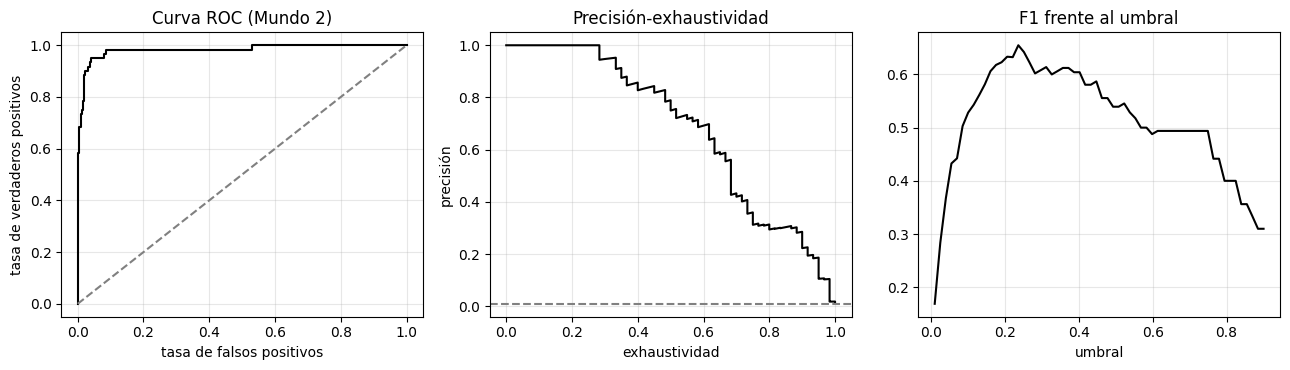

Mejor umbral por F1 en este laboratorio: 0.24 | F1: 0.655


In [6]:
# Curva ROC, curva precisión-exhaustividad y F1 frente al umbral (modelo sin pesos)
p = logit.predict_proba(Xs_pru)[:, 1]
fpr, tpr, _ = roc_curve(ys_pru, p)
pre, rec, _ = precision_recall_curve(ys_pru, p)
umbrales = np.linspace(0.01, 0.9, 60)
f1_u = [f1_score(ys_pru, (p >= u).astype(int), zero_division=0) for u in umbrales]
fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))
ax[0].plot(fpr, tpr, color="black")
ax[0].plot([0, 1], [0, 1], "--", color="gray")
ax[0].set_title("Curva ROC (Mundo 2)")
ax[0].set_xlabel("tasa de falsos positivos")
ax[0].set_ylabel("tasa de verdaderos positivos")
ax[1].plot(rec, pre, color="black")
ax[1].axhline(ys_pru.mean(), ls="--", color="gray")
ax[1].set_title("Precisión-exhaustividad")
ax[1].set_xlabel("exhaustividad")
ax[1].set_ylabel("precisión")
ax[2].plot(umbrales, f1_u, color="black")
ax[2].set_title("F1 frente al umbral")
ax[2].set_xlabel("umbral")
plt.tight_layout()
plt.show()
mejor_u = umbrales[int(np.argmax(f1_u))]
print(
    "Mejor umbral por F1 en este laboratorio:",
    round(mejor_u, 2),
    "| F1:",
    round(max(f1_u), 3),
)

# 4. Preparación de datos de SPY: variables causales y tres objetivos
Las variables usan solo información al cierre del día *t*. Los objetivos miran al futuro. La partición es **cronológica** (70 % / 30 %) con un **embargo de 22 filas** para que los objetivos de entrenamiento no crucen la frontera.

In [7]:
# Variables causales de un activo: solo información conocida al cierre del día t
TICKER = "SPY"
cierre = cierres[TICKER].dropna()
alto, bajo, volumen = (
    altos[TICKER].reindex(cierre.index),
    bajos[TICKER].reindex(cierre.index),
    volumenes[TICKER].reindex(cierre.index),
)
vix = cierres["^VIX"].reindex(cierre.index).ffill()
r = np.log(cierre).diff() * 100  # retorno logarítmico diario en %
X = pd.DataFrame(
    {
        "ret_1": r,
        "ret_5": r.rolling(5).sum(),
        "ret_22": r.rolling(22).sum(),
        "vol_5": r.rolling(5).std(),
        "vol_22": r.rolling(22).std(),
        "vol_66": r.rolling(66).std(),
        "vix": vix,
        "d_vix": vix.diff(5),
        "parkinson": (np.log(alto / bajo) / np.sqrt(4 * np.log(2)) * 100)
        .rolling(5)
        .mean(),
        "dist_sma50": (cierre / cierre.rolling(50).mean() - 1) * 100,
        "rango_22": (cierre - bajo.rolling(22).min())
        / (alto.rolling(22).max() - bajo.rolling(22).min()),
        "d_volumen": np.log(volumen / volumen.rolling(22).mean()),
    }
).loc["2012-01-01":]
VARS = list(X.columns)
print(TICKER, "| variables:", VARS)

SPY | variables: ['ret_1', 'ret_5', 'ret_22', 'vol_5', 'vol_22', 'vol_66', 'vix', 'd_vix', 'parkinson', 'dist_sma50', 'rango_22', 'd_volumen']


In [8]:
# Tres objetivos binarios del mismo activo (todos miran al FUTURO; las variables solo al pasado)
y_dir5 = (cierre.shift(-5) / cierre > 1).astype(
    float
)  # ¿cierra más alto dentro de 5 sesiones?
vol_fut = r.shift(-22).rolling(22).std()  # volatilidad de las próximas 22 sesiones
caida = pd.concat([cierre.shift(-k) / cierre - 1 for k in range(1, 11)], axis=1).min(
    axis=1
)  # peor caída en las próximas 10 sesiones
datos = (
    X.join(y_dir5.rename("dir5"))
    .join(vol_fut.rename("vol_fut"))
    .join(caida.rename("caida"))
    .dropna()
)
corte = int(len(datos) * 0.7)
H = 22  # embargo = horizonte más largo
ent, pru = datos.iloc[: corte - H], datos.iloc[corte:]
umbral_vol = ent["vol_fut"].quantile(0.70)  # el umbral sale SOLO del entrenamiento
for t in (ent, pru):
    t["alta_vol"] = (t["vol_fut"] > umbral_vol).astype(int)
    t["crash"] = (t["caida"] <= -0.04).astype(int)
    t["dir5"] = t["dir5"].astype(int)
print(
    "Entrenamiento:",
    len(ent),
    "filas, hasta",
    ent.index.max().date(),
    "| Prueba:",
    len(pru),
    "filas, desde",
    pru.index.min().date(),
)
for obj in ["dir5", "alta_vol", "crash"]:
    print(
        f"{obj:9s} tasa base entrenamiento {ent[obj].mean():.3f} | prueba "
        f"{pru[obj].mean():.3f}"
    )

Entrenamiento: 2582 filas, hasta 2022-04-05 | Prueba: 1117 filas, desde 2022-05-09
dir5      tasa base entrenamiento 0.624 | prueba 0.601
alta_vol  tasa base entrenamiento 0.300 | prueba 0.353
crash     tasa base entrenamiento 0.088 | prueba 0.103


# 5. Parte III — ¿Sube SPY dentro de 5 sesiones? (Mundo 1: ruido financiero)
La referencia ingenua es **siempre «sube»** (la tasa base). Un modelo útil debe superarla en AUC y en exactitud balanceada.

In [9]:
# Regresión logística para la dirección a 5 sesiones, frente a la referencia ingenua
mod = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)).fit(
    ent[VARS], ent["dir5"]
)
p_dir = mod.predict_proba(pru[VARS])[:, 1]
y_dir = (p_dir >= 0.5).astype(int)
print("Tasa base de «sube» en la prueba:", round(pru["dir5"].mean(), 3))
print(
    "Referencia «siempre sube»: exactitud",
    round(accuracy_score(pru["dir5"], np.ones(len(pru))), 3),
    "| exactitud balanceada",
    0.5,
)
print(
    "Logística: exactitud",
    round(accuracy_score(pru["dir5"], y_dir), 3),
    "| exactitud balanceada",
    round(balanced_accuracy_score(pru["dir5"], y_dir), 3),
    "| AUC",
    round(roc_auc_score(pru["dir5"], p_dir), 3),
)
print(confusion_matrix(pru["dir5"], y_dir))

Tasa base de «sube» en la prueba: 0.601
Referencia «siempre sube»: exactitud 0.601 | exactitud balanceada 0.5
Logística: exactitud 0.602 | exactitud balanceada 0.501 | AUC 0.497
[[  1 445]
 [  0 671]]


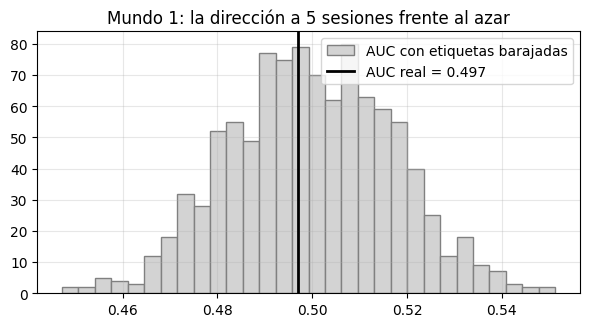

AUC real: 0.497 | AUC del azar: media 0.5 | percentil 95: 0.528 | valor p: 0.56


In [10]:
# Prueba de permutación: ¿qué AUC produce el azar con estas mismas etiquetas?
auc_real = roc_auc_score(pru["dir5"], p_dir)
auc_azar = np.array(
    [roc_auc_score(rng.permutation(pru["dir5"].values), p_dir) for _ in range(1000)]
)
valor_p = (auc_azar >= auc_real).mean()
plt.figure(figsize=(7, 3.4))
plt.hist(
    auc_azar,
    bins=30,
    color="lightgray",
    edgecolor="gray",
    label="AUC con etiquetas barajadas",
)
plt.axvline(auc_real, color="black", lw=2, label=f"AUC real = {auc_real:.3f}")
plt.legend()
plt.title("Mundo 1: la dirección a 5 sesiones frente al azar")
plt.show()
print(
    "AUC real:",
    round(auc_real, 3),
    "| AUC del azar: media",
    round(auc_azar.mean(), 3),
    "| percentil 95:",
    round(np.percentile(auc_azar, 95), 3),
    "| valor p:",
    round(valor_p, 3),
)

# 6. Parte IV — ¿Será agitado el próximo mes? (Mundo 3: señal real)
Objetivo: la volatilidad de las próximas 22 sesiones supera el **percentil 70 del entrenamiento**. Aquí sí hay estructura: la volatilidad se agrupa (Tema 10) y el VIX la anticipa.

In [11]:
# Mismo código, otro objetivo: régimen de alta volatilidad
mod_v = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)).fit(
    ent[VARS], ent["alta_vol"]
)
p_v = mod_v.predict_proba(pru[VARS])[:, 1]
print("Tasa base de «alta volatilidad» en la prueba:", round(pru["alta_vol"].mean(), 3))
filas = []
for u in [0.3, 0.5, 0.7]:
    y_hat = (p_v >= u).astype(int)
    filas.append(
        [
            u,
            accuracy_score(pru["alta_vol"], y_hat),
            precision_score(pru["alta_vol"], y_hat),
            recall_score(pru["alta_vol"], y_hat),
            f1_score(pru["alta_vol"], y_hat),
        ]
    )
print(
    pd.DataFrame(
        filas, columns=["umbral", "exactitud", "precisión", "exhaustividad", "F1"]
    )
    .round(3)
    .to_string(index=False)
)
print(
    "AUC-ROC:",
    round(roc_auc_score(pru["alta_vol"], p_v), 3),
    "| AUC-PR:",
    round(average_precision_score(pru["alta_vol"], p_v), 3),
    "| Brier:",
    round(brier_score_loss(pru["alta_vol"], p_v), 3),
)
print(confusion_matrix(pru["alta_vol"], (p_v >= 0.5).astype(int)))

Tasa base de «alta volatilidad» en la prueba: 0.353
 umbral  exactitud  precisión  exhaustividad    F1
    0.3      0.757      0.624          0.787 0.696
    0.5      0.788      0.801          0.530 0.638
    0.7      0.748      0.895          0.325 0.477
AUC-ROC: 0.833 | AUC-PR: 0.777 | Brier: 0.151


[[671  52]
 [185 209]]


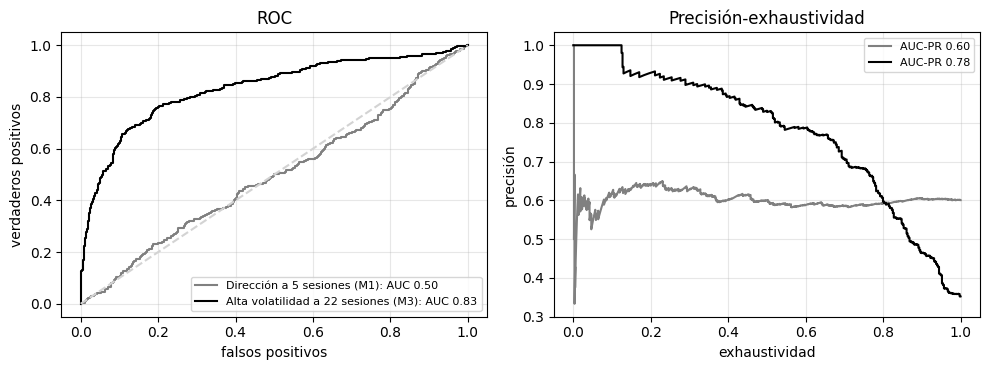

In [12]:
# Curvas ROC y precisión-exhaustividad: Mundo 1 (dirección) frente a Mundo 3 (volatilidad)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
for nombre, y, p, c in [
    ("Dirección a 5 sesiones (M1)", pru["dir5"], p_dir, "gray"),
    ("Alta volatilidad a 22 sesiones (M3)", pru["alta_vol"], p_v, "black"),
]:
    f, t, _ = roc_curve(y, p)
    ax[0].plot(f, t, color=c, label=f"{nombre}: AUC {roc_auc_score(y, p):.2f}")
    pr, rc, _ = precision_recall_curve(y, p)
    ax[1].plot(rc, pr, color=c, label=f"AUC-PR {average_precision_score(y, p):.2f}")
ax[0].plot([0, 1], [0, 1], "--", color="lightgray")
ax[0].legend(fontsize=8)
ax[0].set_title("ROC")
ax[0].set_xlabel("falsos positivos")
ax[0].set_ylabel("verdaderos positivos")
ax[1].set_title("Precisión-exhaustividad")
ax[1].set_xlabel("exhaustividad")
ax[1].set_ylabel("precisión")
ax[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

# 7. Parte V — El umbral es una decisión de negocio
Si un falso negativo (no cubrir antes de un periodo agitado) cuesta **3** veces un falso positivo (cubrir de más), el umbral óptimo de probabilidad es costo_FP / (costo_FP + costo_FN) = 1/4 = 0,25. El umbral se **elige en validación** (la última parte cronológica del entrenamiento) y se evalúa una sola vez en la prueba.

Umbral teórico: 0.25 | umbral elegido en validación: 0.25
Costo total en la prueba con umbral 0.50: 607.0 | con el umbral elegido: 453.0
Exhaustividad con el umbral elegido: 0.848 | precisión: 0.55


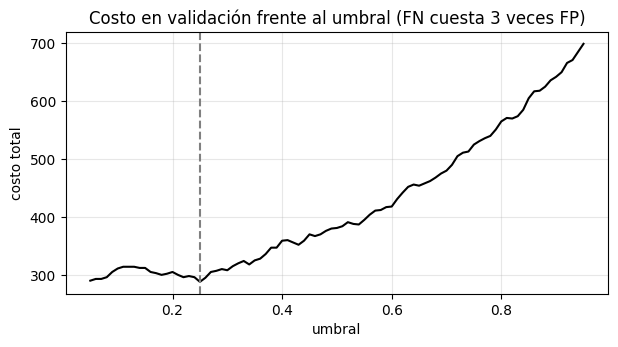

In [13]:
# Umbral por costos: se elige en validación (20 % final del entrenamiento, con embargo) y se evalúa en la prueba
c_fp, c_fn = 1.0, 3.0
corte_v = int(len(ent) * 0.8)
ent2, val = ent.iloc[: corte_v - H], ent.iloc[corte_v:]
m2 = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)).fit(
    ent2[VARS], ent2["alta_vol"]
)
p_val = m2.predict_proba(val[VARS])[:, 1]
us = np.linspace(0.05, 0.95, 91)
costo_val = [
    c_fp * ((p_val >= u) & (val["alta_vol"] == 0)).sum()
    + c_fn * ((p_val < u) & (val["alta_vol"] == 1)).sum()
    for u in us
]
u_opt = us[int(np.argmin(costo_val))]
y_hat = (p_v >= u_opt).astype(int)
costo_pru = (
    c_fp * ((y_hat == 1) & (pru["alta_vol"] == 0)).sum()
    + c_fn * ((y_hat == 0) & (pru["alta_vol"] == 1)).sum()
)
costo_05 = (
    c_fp * (((p_v >= 0.5)) & (pru["alta_vol"] == 0)).sum()
    + c_fn * (((p_v < 0.5)) & (pru["alta_vol"] == 1)).sum()
)
print(
    "Umbral teórico:",
    c_fp / (c_fp + c_fn),
    "| umbral elegido en validación:",
    round(u_opt, 2),
)
print(
    "Costo total en la prueba con umbral 0.50:",
    costo_05,
    "| con el umbral elegido:",
    costo_pru,
)
print(
    "Exhaustividad con el umbral elegido:",
    round(recall_score(pru["alta_vol"], y_hat), 3),
    "| precisión:",
    round(precision_score(pru["alta_vol"], y_hat), 3),
)
plt.figure(figsize=(7, 3.4))
plt.plot(us, costo_val, color="black")
plt.axvline(u_opt, ls="--", color="gray")
plt.title("Costo en validación frente al umbral (FN cuesta 3 veces FP)")
plt.xlabel("umbral")
plt.ylabel("costo total")
plt.show()

# 8. Resumen
- La **exactitud** se lee siempre contra la **tasa base**; con eventos raros engaña.
- **AUC-ROC** mide la capacidad de ordenar; **AUC-PR** es más honesta con pocos positivos (el azar vale la tasa base).
- El **umbral** no es del modelo: es una **decisión de costos**, y se elige sin tocar la prueba.
- Mundo 1: la dirección a 5 sesiones no se distingue del azar. Mundo 3: el régimen de volatilidad sí se anticipa.